# Solutions to notebook 11: Vector calculus in Cartesian, cylindrical and spherical coordinates

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/solutions/11_vector_calculus.ipynb)

Worked solutions to the exercises at the end of [notebook 11](../notebooks/11_vector_calculus.ipynb).
Try each exercise yourself before reading its solution: the struggle is where the learning happens.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from sympy.vector import CoordSys3D, curl, divergence, gradient

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

The coordinate systems and the function `plain` are the ones defined in the lesson.

In [2]:
N = CoordSys3D("N")
C = CoordSys3D("C", transformation="cylindrical", variable_names=("r", "theta", "z"))
S = CoordSys3D("S", transformation="spherical", variable_names=("r", "theta", "phi"))

r, theta, z, phi = sp.symbols("r theta z phi", positive=True)

def plain(expr, system):
    """Replace the system's coordinates by ordinary symbols, for readable output."""
    names = {"C": (r, theta, z), "S": (r, theta, phi)}[str(system)]
    return expr.subs(dict(zip(system.base_scalars(), names)))

## Exercise 1

Derive the divergence of a vector field in spherical coordinates and compare it with your
textbook.

Use undefined functions for the three components, as in section 11.1, so the result holds for
any field. In the system `S` the unit vectors `S.i`, `S.j`, `S.k` point in the $r$, $\theta$
and $\phi$ directions, and $\theta$ is the polar angle.

In [3]:
F_r, F_theta, F_phi = (sp.Function(name)(S.r, S.theta, S.phi) for name in ("F_r", "F_theta", "F_phi"))
F = F_r * S.i + F_theta * S.j + F_phi * S.k

divergence_sph = sp.expand(sp.simplify(divergence(F)))
plain(divergence_sph, S)

                                                    ∂                     ∂    ↪
                                                    ──(Fₜₕₑₜₐ(r, θ, φ))   ──(F ↪
∂                 2⋅Fᵣ(r, θ, φ)   Fₜₕₑₜₐ(r, θ, φ)   ∂θ                    ∂φ   ↪
──(Fᵣ(r, θ, φ)) + ───────────── + ─────────────── + ─────────────────── + ──── ↪
∂r                      r            r⋅tan(θ)                r               r ↪

↪            
↪ ᵩ(r, θ, φ))
↪            
↪ ───────────
↪ ⋅sin(θ)    

**Verify** against the compact textbook form

$$\nabla\cdot\mathbf{F} = \frac{1}{r^2}\frac{\partial}{\partial r}\!\left(r^2 F_r\right)
+ \frac{1}{r\sin\theta}\frac{\partial}{\partial\theta}\!\left(\sin\theta\,F_\theta\right)
+ \frac{1}{r\sin\theta}\frac{\partial F_\phi}{\partial\phi}$$

and with two fields whose divergence is known: the position vector $r\,\mathbf{e}_r$
(divergence 3, as for $x\,\mathbf{i} + y\,\mathbf{j} + z\,\mathbf{k}$) and the inverse-square
field $\mathbf{e}_r/r^2$ (no sources away from the origin).

In [4]:
G_r, G_theta, G_phi = (sp.Function(name)(r, theta, phi) for name in ("F_r", "F_theta", "F_phi"))
textbook_div = (sp.diff(r**2 * G_r, r) / r**2
                + sp.diff(sp.sin(theta) * G_theta, theta) / (r * sp.sin(theta))
                + sp.diff(G_phi, phi) / (r * sp.sin(theta)))
assert sp.simplify(plain(divergence_sph, S) - textbook_div) == 0

assert divergence(S.r * S.i) == 3
assert sp.simplify(divergence(S.i / S.r**2)) == 0

**Answer.** Expanded,

$$\nabla\cdot\mathbf{F} = \frac{\partial F_r}{\partial r} + \frac{2F_r}{r}
+ \frac{1}{r}\frac{\partial F_\theta}{\partial\theta} + \frac{F_\theta}{r\tan\theta}
+ \frac{1}{r\sin\theta}\frac{\partial F_\phi}{\partial\phi},$$

which is the textbook formula with its product-rule derivatives carried out. The terms
$2F_r/r$ and $F_\theta/(r\tan\theta)$ contain no derivative of the field. They come from the
changing size of the area elements, which grow as $r^2\sin\theta$.

## Exercise 2

Repeat 11.4 for a long hollow cylinder. The heat flow per unit length should be
$2\pi k (T_1 - T_2)/\ln(r_2/r_1)$.

With axial symmetry and a long cylinder $T = T(r)$. SymPy reduces $\nabla^2 T = 0$ in the
cylindrical system to an ordinary differential equation.

In [5]:
T = sp.Function("T")
conduction = plain(sp.simplify(divergence(gradient(T(C.r)))), C).doit()
conduction

            d       
 2          ──(T(r))
d           dr      
───(T(r)) + ────────
  2            r    
dr                  

In [6]:
r1, r2, T1, T2, k = sp.symbols("r_1 r_2 T_1 T_2 k", positive=True)

T_cyl = sp.dsolve(conduction, T(r), ics={T(r1): T1, T(r2): T2}).rhs
heat_flow = sp.simplify(-k * 2 * sp.pi * r * sp.diff(T_cyl, r))      # Fourier's law × area per unit length
sp.expand_log(T_cyl, force=True), heat_flow

⎛(T₁ - T₂)⋅log(r)    -T₁⋅log(r₂) + T₂⋅log(r₁)  2⋅π⋅k⋅(-T₁ + T₂)⎞
⎜───────────────── + ────────────────────────, ────────────────⎟
⎜log(r₁) - log(r₂)      log(r₁) - log(r₂)             ⎛r₁⎞     ⎟
⎜                                                  log⎜──⎟     ⎟
⎝                                                     ⎝r₂⎠     ⎠

In [7]:
# verify: both boundary temperatures are met, the heat flow is the same through every
# cylindrical surface, and it matches the expected formula
assert sp.simplify(T_cyl.subs(r, r1) - T1) == 0 and sp.simplify(T_cyl.subs(r, r2) - T2) == 0
assert not heat_flow.has(r)
assert sp.simplify(heat_flow - 2 * sp.pi * k * (T1 - T2) / sp.log(r2 / r1)) == 0

# a thin wall (thickness delta -> 0) must behave like a flat slab: area × k × ΔT / thickness
delta = sp.symbols("delta", positive=True)
slab = 2 * sp.pi * r1 * k * (T1 - T2) / delta
assert sp.limit(heat_flow.subs(r2, r1 + delta) / slab, delta, 0) == 1

**Answer.** The temperature varies logarithmically,

$$T(r) = T_1 - (T_1 - T_2)\,\frac{\ln(r/r_1)}{\ln(r_2/r_1)}, \qquad
\frac{Q}{L} = \frac{2\pi k\,(T_1 - T_2)}{\ln(r_2/r_1)} ,$$

in W/m, as expected. The heat flow does not depend on $r$: the flux falls as $1/r$ while the
area grows as $r$. For a thin wall the result reduces to the flat-slab formula.

In [8]:
assert sp.simplify(T_cyl - (T1 - (T1 - T2) * sp.log(r / r1) / sp.log(r2 / r1))) == 0

## Exercise 3

Add a circulation $\Gamma$ to the cylinder flow: $\phi \to \phi + \dfrac{\Gamma}{2\pi}\theta$.
Show that the drag integral is still zero but $\int_0^{2\pi} C_p\sin\theta\,d\theta = 2\Gamma/(Ua)$,
which corresponds to a force of magnitude $\rho U\Gamma$ per unit length (the Kutta–Joukowski
lift). Which way does it point for $\Gamma > 0$?

In [9]:
U, a, Gamma, rho = sp.symbols("U a Gamma rho", positive=True)

potential = U * (C.r + a**2 / C.r) * sp.cos(C.theta) + Gamma / (2 * sp.pi) * C.theta
assert sp.simplify(divergence(gradient(potential))) == 0          # Laplace's equation still holds

flow = gradient(potential)
v_r = sp.simplify(flow.dot(C.i))
v_theta = sp.simplify(flow.dot(C.j))
assert v_r.subs(C.r, a) == 0                                      # still no flow through the wall

surface_speed = sp.expand(plain(v_theta.subs(C.r, a), C))
surface_speed

  Γ               
───── - 2⋅U⋅sin(θ)
2⋅π⋅a             

The extra term $\Gamma/(2\pi a)$ is a uniform swirl around the cylinder. The same integrals as
in section 11.5 give the pressure force.

In [10]:
C_p = sp.expand(1 - (surface_speed / U) ** 2)
drag = sp.integrate(C_p * sp.cos(theta), (theta, 0, 2 * sp.pi))
lift = sp.integrate(C_p * sp.sin(theta), (theta, 0, 2 * sp.pi))
C_p, drag, lift

⎛       2                                         ⎞
⎜      Γ        2⋅Γ⋅sin(θ)        2            2⋅Γ⎟
⎜- ────────── + ────────── - 4⋅sin (θ) + 1, 0, ───⎟
⎜     2  2  2     π⋅U⋅a                        U⋅a⎟
⎝  4⋅π ⋅U ⋅a                                      ⎠

Pressure pushes on the surface along the inward normal, so the force per unit length in the
$y$ direction is $F_y = -\tfrac12\rho U^2 a\displaystyle\int_0^{2\pi} C_p\sin\theta\,d\theta$.

In [11]:
lift_force = sp.simplify(-sp.Rational(1, 2) * rho * U**2 * a * lift)

# verify: zero drag, the hand-integrated lift, the Kutta–Joukowski theorem, and that Gamma
# really is the circulation (the line integral of the velocity around the cylinder)
assert drag == 0
assert sp.simplify(lift - 2 * Gamma / (U * a)) == 0
assert sp.simplify(lift_force + rho * U * Gamma) == 0
assert sp.simplify(sp.integrate(surface_speed * a, (theta, 0, 2 * sp.pi)) - Gamma) == 0
lift_force

-Γ⋅U⋅ρ

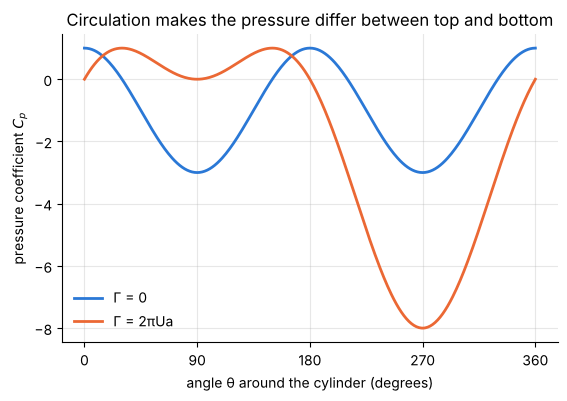

In [12]:
# pressure distribution for U = a = 1, without circulation and with Gamma = 2 pi U a
C_p_fun = sp.lambdify((theta, Gamma), C_p.subs({U: 1, a: 1}), "numpy")
angles = np.linspace(0, 2 * np.pi, 361)

fig, ax = plt.subplots()
ax.plot(np.degrees(angles), C_p_fun(angles, 0), label="Γ = 0")
ax.plot(np.degrees(angles), C_p_fun(angles, 2 * np.pi), label="Γ = 2πUa")
ax.set(xlabel="angle θ around the cylinder (degrees)", ylabel="pressure coefficient $C_p$",
       title="Circulation makes the pressure differ between top and bottom", xticks=range(0, 361, 90))
ax.legend(frameon=False, loc="lower left");

**Answer.** On the surface $v_\theta = -2U\sin\theta + \dfrac{\Gamma}{2\pi a}$. The drag
integral is still zero, because the pressure remains symmetric front to back. The lift integral
is

$$\int_0^{2\pi} C_p\sin\theta\,d\theta = \frac{2\Gamma}{Ua} \neq 0 ,$$

which corresponds to a force per unit length $F_y = -\rho U\Gamma$. Its magnitude
$\rho U\Gamma$ is the Kutta–Joukowski lift. The sign is negative here because a positive
$\Gamma$ in this potential is a counter-clockwise swirl: it slows the flow over the top
($\theta = 90°$) and speeds it up underneath ($\theta = 270°$), so the pressure is higher on
top, as the plot shows. A clockwise circulation gives upward lift.

## Exercise 4

Show that the rigid-body rotation $\mathbf{u} = \Omega r\,\mathbf{e}_\theta$ has vorticity
$2\Omega$, while the free vortex $\mathbf{u} = \dfrac{\Gamma}{2\pi r}\,\mathbf{e}_\theta$ has none.

In [13]:
Omega = sp.symbols("Omega", positive=True)

rigid = Omega * C.r * C.j
free = Gamma / (2 * sp.pi * C.r) * C.j

curl(rigid), curl(free)

((2⋅Ω) k_C, 0)

**Verify** by repeating the calculation in Cartesian coordinates, where
$\mathbf{e}_\theta = (-y\,\mathbf{i} + x\,\mathbf{j})/r$ and $r^2 = x^2 + y^2$.

In [14]:
assert curl(rigid) == 2 * Omega * C.k
assert curl(free) == sp.vector.Vector.zero

rigid_cartesian = Omega * (-N.y * N.i + N.x * N.j)
free_cartesian = Gamma / (2 * sp.pi) * (-N.y * N.i + N.x * N.j) / (N.x**2 + N.y**2)
assert curl(rigid_cartesian) == 2 * Omega * N.k
assert sp.simplify(curl(free_cartesian).dot(N.k)) == 0

**Answer.** The rigid-body rotation has vorticity $2\Omega\,\mathbf{e}_z$, twice the angular
velocity, the same at every point. The free vortex has zero vorticity everywhere except on the
axis $r = 0$, where the velocity is singular. Its fluid elements travel in circles without
spinning about their own centres. All of its circulation $\Gamma$ is concentrated on the axis.

## Exercise 5

For Couette flow between rotating cylinders, $u_\theta = Ar + B/r$, use the radial result
of 11.6 to find the radial pressure gradient (steady flow, density $\rho$; the radial
viscous term is zero).

First rebuild the radial component of the convective acceleration from section 11.6, using the
identity $(\mathbf{u}\cdot\nabla)\mathbf{u} = \nabla\!\left(\tfrac12\,\mathbf{u}\cdot\mathbf{u}\right) - \mathbf{u}\times(\nabla\times\mathbf{u})$.

In [15]:
u_r, u_t, u_zz = (sp.Function(name)(C.r, C.theta, C.z) for name in ("u_r", "u_theta", "u_z"))
u = u_r * C.i + u_t * C.j + u_zz * C.k

acceleration = gradient(u.dot(u) / 2) - u.cross(curl(u))
radial = sp.expand(sp.simplify(acceleration.dot(C.i)))
plain(radial, C)

                                                                               ↪
                                                                   2           ↪
            ∂                              ∂                 uₜₕₑₜₐ (r, θ, z)  ↪
uᵣ(r, θ, z)⋅──(uᵣ(r, θ, z)) + u_z(r, θ, z)⋅──(uᵣ(r, θ, z)) - ────────────────  ↪
            ∂r                             ∂z                       r          ↪

↪                   ∂              
↪   uₜₕₑₜₐ(r, θ, z)⋅──(uᵣ(r, θ, z))
↪                   ∂θ             
↪ + ───────────────────────────────
↪                  r               

In Couette flow $u_r = u_z = 0$ and $u_\theta$ depends on $r$ only. Substitute and evaluate
the derivatives.

In [16]:
A, B = sp.symbols("A B", real=True)

couette = A * C.r + B / C.r
radial_couette = sp.factor(radial.subs({u_r: 0, u_zz: 0, u_t: couette}).doit())
plain(radial_couette, C)

           2 
 ⎛   2    ⎞  
-⎝A⋅r  + B⎠  
─────────────
      3      
     r       

Only the centripetal term $-u_\theta^2/r$ survives. The flow is steady, and the radial viscous
term vanishes because $u_r = 0$ and nothing depends on $\theta$, so the radial momentum
equation is $\rho\,(\mathbf{u}\cdot\nabla\mathbf{u})_r = -\dfrac{dp}{dr}$.

In [17]:
dp_dr = plain(-rho * radial_couette, C)
pressure = sp.integrate(sp.expand(dp_dr), r)            # up to an additive constant
dp_dr, pressure

⎛            2                                 ⎞
⎜  ⎛   2    ⎞    2  2                       2  ⎟
⎜ρ⋅⎝A⋅r  + B⎠   A ⋅r ⋅ρ                    B ⋅ρ⎟
⎜─────────────, ─────── + 2⋅A⋅B⋅ρ⋅log(r) - ────⎟
⎜      3           2                          2⎟
⎝     r                                    2⋅r ⎠

**Verify** in three independent ways: a direct Cartesian calculation of
$(\mathbf{u}\cdot\nabla)\mathbf{u}$, which needs no curvilinear formulas, and the two limiting
cases of exercise 4.

In [18]:
assert sp.simplify(dp_dr - rho * (A * r + B / r) ** 2 / r) == 0          # rho * u_theta^2 / r

# Cartesian: u = (A + B/r^2) (-y, x); the acceleration should be -(A + B/r^2)^2 (x, y)
swirl = A + B / (N.x**2 + N.y**2)
ux, uy = -swirl * N.y, swirl * N.x
ax_cartesian = ux * sp.diff(ux, N.x) + uy * sp.diff(ux, N.y)
ay_cartesian = ux * sp.diff(uy, N.x) + uy * sp.diff(uy, N.y)
assert sp.simplify(ax_cartesian + swirl**2 * N.x) == 0 and sp.simplify(ay_cartesian + swirl**2 * N.y) == 0

# rigid rotation (B = 0): dp/dr = rho * A^2 * r, the pressure in a spinning bucket
assert sp.simplify(dp_dr.subs(B, 0) - rho * A**2 * r) == 0
# free vortex (A = 0) is irrotational, so Bernoulli holds: p + rho * u^2 / 2 is constant
assert sp.simplify(sp.diff(pressure.subs(A, 0) + rho * (B / r) ** 2 / 2, r)) == 0

**Answer.**

$$\frac{dp}{dr} = \frac{\rho\,u_\theta^2}{r} = \frac{\rho\,(Ar^2 + B)^2}{r^3}, \qquad
p(r) = \rho\left(\frac{A^2 r^2}{2} + 2AB\ln r - \frac{B^2}{2r^2}\right) + \text{constant}.$$

The pressure always rises outwards, whatever the signs of $A$ and $B$: the pressure gradient
supplies the centripetal force that keeps the fluid moving in circles.